# Task 1 · Exploratory Data Analysis on Retail Sales Data

**Track:** Data Analytics · Level 1
**Dataset:** Retail Sales Dataset (Kaggle) — 1,000 transactions, one per customer, 2023
**Tools:** Python, pandas, matplotlib, seaborn

**Goal:** uncover sales patterns, customer behaviour and actionable business insights.

> **A note on the data.** This file has individual *transactions* but only 3 product
> *categories* (Beauty, Clothing, Electronics) and no product names. So the checklist item
> "top 10 best-selling products" is adapted: I rank **categories** and **price points**
> (the 5 distinct unit prices in the data) instead. Every Customer ID also appears exactly
> once, so repeat-customer analysis isn't possible.

## 1. Setup and initial inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("retail_sales_dataset.csv")
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (1000, 9)


In [2]:
# Column data types
df.dtypes

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

In [3]:
# Null values and duplicate rows
print("Nulls per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique Customer IDs:", df["Customer ID"].nunique(), "out of", len(df), "rows")

Nulls per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0
Unique Customer IDs: 1000 out of 1000 rows


In [4]:
df.head()

   Transaction ID        Date  ... Price per Unit Total Amount
0               1  2023-11-24  ...             50          150
1               2  2023-02-27  ...            500         1000
2               3  2023-01-13  ...             30           30
3               4  2023-05-21  ...            500          500
4               5  2023-05-06  ...             50          100

[5 rows x 9 columns]

**Observations**

- The dataset has **1,000 rows × 9 columns**, with **no missing values and no duplicate rows**, so no cleaning is needed.
- `Date` is stored as text (a string/`object` column, not a date), so it must be converted to a datetime before any time analysis.
- `Customer ID` is unique on every row: each customer bought exactly once, so we can analyse *who buys what*, but not *loyalty or repeat purchases*.

## 2. Preparing the data

In [5]:
# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Derived columns used throughout the notebook
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"],
)

print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Rows dated in 2024:", (df["Date"].dt.year == 2024).sum())

# Sanity check: does Total Amount = Quantity x Price per Unit on every row?
print("Total Amount == Quantity x Price on all rows:",
      (df["Quantity"] * df["Price per Unit"] == df["Total Amount"]).all())

Date range: 2023-01-01 to 2024-01-01
Rows dated in 2024: 2
Total Amount == Quantity x Price on all rows: True


**Observations**

- The data covers all of 2023, plus **2 rows dated 1 Jan 2024**. For the monthly and quarterly trend charts I use 2023 only (`df_2023`), otherwise January 2024 would appear as a misleading 13th month with 2 sales.
- `Total Amount` always equals `Quantity × Price per Unit`, so the data is internally consistent.
- Age groups were created so the demographic charts are readable (18-25, 26-35, 36-45, 46-55, 56-65).

In [6]:
# 2023 only, for time-series analysis
df_2023 = df[df["Date"] < "2024-01-01"].copy()
len(df_2023)

998

## 3. Descriptive statistics

In [7]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
}).round(2)
stats

                  mean  median  mode     std  min   max
Age              41.39    42.0  43.0   13.68   18    64
Quantity          2.51     3.0   4.0    1.13    1     4
Price per Unit  179.89    50.0  50.0  189.68   25   500
Total Amount    456.00   135.0  50.0  560.00   25  2000

**Observations**

- **Total Amount** is right-skewed: the mean (**456**) is more than 3× the median (**135**), and the standard deviation (560) is larger than the mean. A minority of large purchases pull the average up, so the *median* describes a typical purchase better than the mean.
- **Price per Unit** is split into two worlds: the mode is 50 and the median is 50, yet the max is 500. The data has only 5 distinct prices (25, 30, 50, 300, 500), explored later.
- **Age** is symmetric (mean 41.4, median 42, range 18-64), so customers are spread evenly across adult ages.
- **Quantity** ranges from 1 to 4 items per transaction (mean 2.5).

## 4. Time series analysis

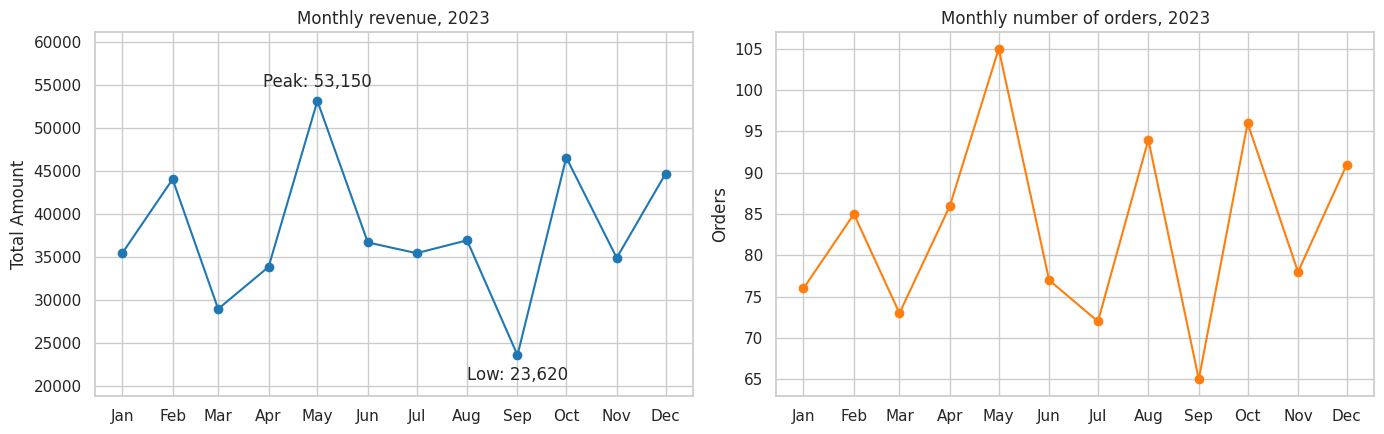

            revenue  orders
Month                      
2023-01-01    35450      76
2023-02-01    44060      85
2023-03-01    28990      73
2023-04-01    33870      86
2023-05-01    53150     105
2023-06-01    36715      77
2023-07-01    35465      72
2023-08-01    36960      94
2023-09-01    23620      65
2023-10-01    46580      96
2023-11-01    34920      78
2023-12-01    44690      91

In [8]:
monthly = df_2023.groupby("Month").agg(
    revenue=("Total Amount", "sum"),
    orders=("Transaction ID", "count"),
)
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(monthly.index, monthly["revenue"], marker="o", color="tab:blue")
axes[0].set_title("Monthly revenue, 2023")
axes[0].set_ylabel("Total Amount")
peak = monthly["revenue"].idxmax(); low = monthly["revenue"].idxmin()
axes[0].annotate(f"Peak: {monthly['revenue'].max():,}", (peak, monthly["revenue"].max()),
                 textcoords="offset points", xytext=(0, 10), ha="center")
axes[0].annotate(f"Low: {monthly['revenue'].min():,}", (low, monthly["revenue"].min()),
                 textcoords="offset points", xytext=(0, -18), ha="center")
axes[0].set_ylim(monthly["revenue"].min() * 0.8, monthly["revenue"].max() * 1.15)

axes[1].plot(monthly.index, monthly["orders"], marker="o", color="tab:orange")
axes[1].set_title("Monthly number of orders, 2023")
axes[1].set_ylabel("Orders")

for ax in axes:
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
plt.tight_layout()
plt.show()
monthly

**Observations**

- Revenue is **volatile with no steady growth**: it swings between **23,620 (September)** and **53,150 (May)**.
- **May is the clear peak** (53,150 revenue and 105 orders, the most of any month). **September is the weakest** (23,620 revenue, 65 orders).
- Order counts and revenue mostly move together, so month-to-month swings come mainly from *how many people buy*, not from big changes in basket value. The exception is February: only 85 orders but 44,060 revenue (average 518 per order, the highest of the year).
- Late-year recovery: October (46,580) and December (44,690) are both strong.

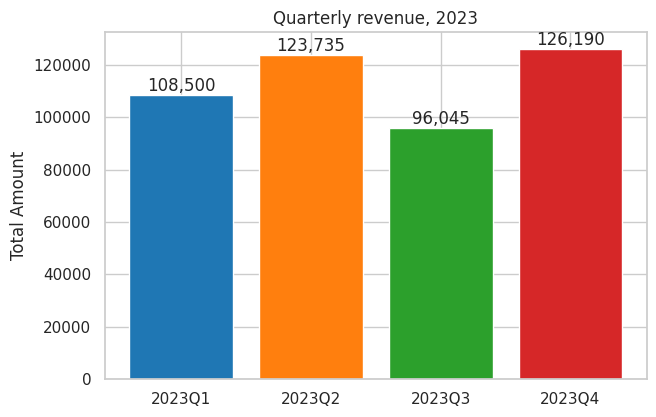

         revenue  orders  avg_order_value
Quarter                                  
2023Q1    108500     234            463.7
2023Q2    123735     268            461.7
2023Q3     96045     231            415.8
2023Q4    126190     265            476.2

In [9]:
quarterly = df_2023.groupby("Quarter").agg(
    revenue=("Total Amount", "sum"),
    orders=("Transaction ID", "count"),
)
quarterly["avg_order_value"] = (quarterly["revenue"] / quarterly["orders"]).round(1)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(quarterly.index.astype(str), quarterly["revenue"], color=sns.color_palette("tab10", 4))
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Quarterly revenue, 2023")
ax.set_ylabel("Total Amount")
plt.show()
quarterly

**Observations**

- **Q4 is the strongest quarter (126,190)** and **Q3 the weakest (96,045)**, a gap of about 31%.
- Q2 (123,735) is almost as strong as Q4, driven by May.
- Caveat: this is **one year of data**, so I can say Q3 was weak in 2023, but can't confirm a recurring seasonal pattern without more years.

## 5. Customer demographics

Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64


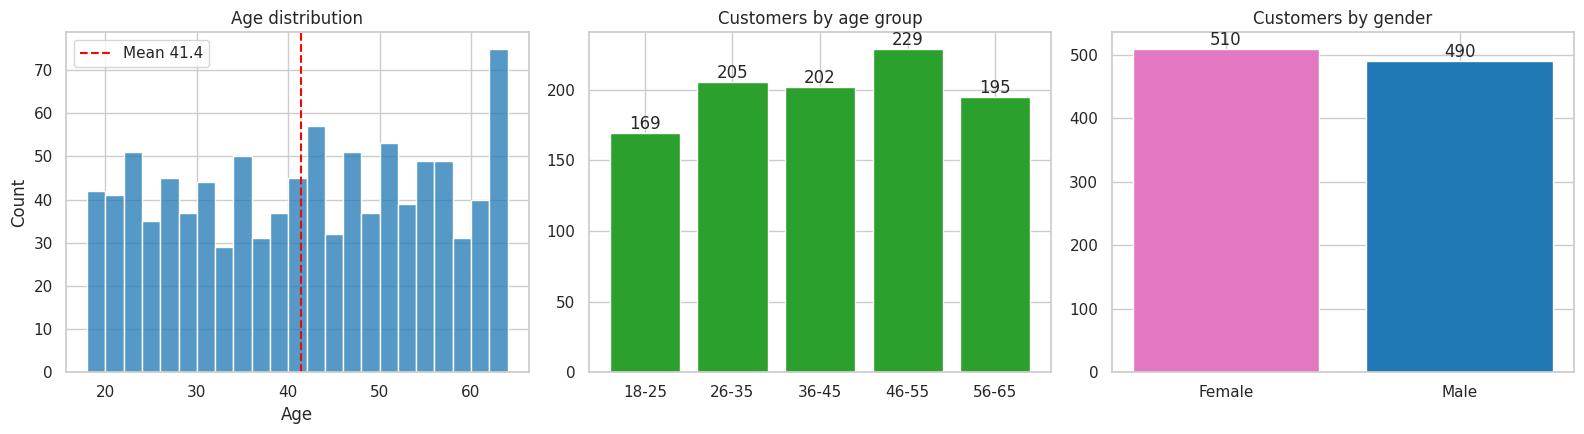

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Age distribution
sns.histplot(df["Age"], bins=23, ax=axes[0], color="tab:blue")
axes[0].axvline(df["Age"].mean(), color="red", linestyle="--", label=f"Mean {df['Age'].mean():.1f}")
axes[0].set_title("Age distribution"); axes[0].legend()

# Age groups
age_counts = df["Age Group"].value_counts().sort_index()
bars = axes[1].bar(age_counts.index.astype(str), age_counts.values, color="tab:green")
axes[1].bar_label(bars)
axes[1].set_title("Customers by age group")

# Gender
gender_counts = df["Gender"].value_counts()
bars = axes[2].bar(gender_counts.index, gender_counts.values, color=["tab:pink", "tab:blue"])
axes[2].bar_label(bars)
axes[2].set_title("Customers by gender")
plt.tight_layout()
plt.show()

print((df["Gender"].value_counts(normalize=True) * 100).round(1))

**Observations**

- Customers are spread **fairly evenly across age groups**; the largest is 46-55 (**229** customers) and the smallest is 18-25 (**169**), the only group noticeably smaller than the rest.
- Gender is almost balanced: **51% female (510)** and **49% male (490)**. Average age is the same for both (about 41).
- There is no single dominant demographic, so the business serves a broad adult market.

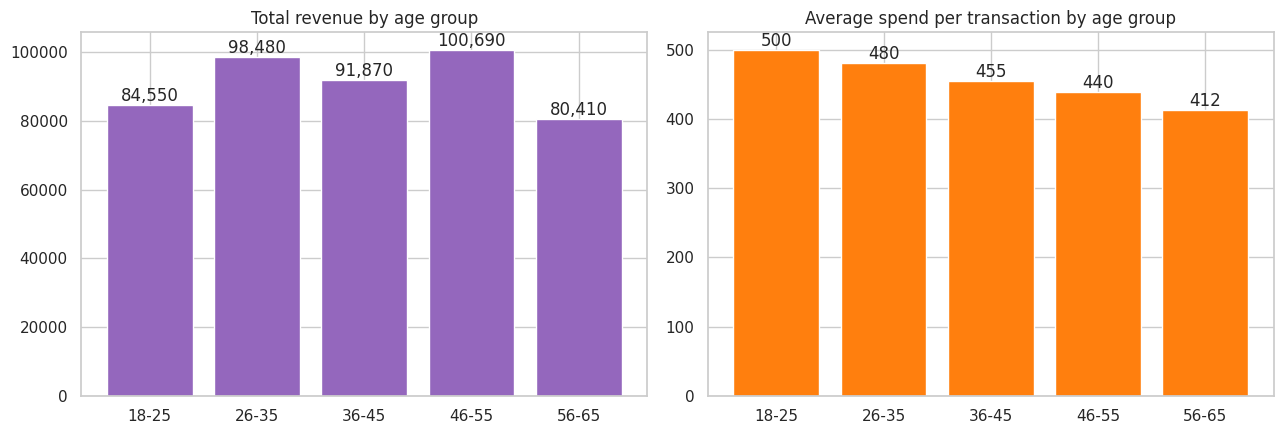

           sum   mean  count
Gender                      
Female  232840  456.5    510
Male    223160  455.4    490

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

spend_age = df.groupby("Age Group", observed=True)["Total Amount"].agg(["sum", "mean"])
bars = axes[0].bar(spend_age.index.astype(str), spend_age["sum"], color="tab:purple")
axes[0].bar_label(bars, fmt="{:,.0f}")
axes[0].set_title("Total revenue by age group")

bars = axes[1].bar(spend_age.index.astype(str), spend_age["mean"], color="tab:orange")
axes[1].bar_label(bars, fmt="{:,.0f}")
axes[1].set_title("Average spend per transaction by age group")
plt.tight_layout()
plt.show()

df.groupby("Gender")["Total Amount"].agg(["sum", "mean", "count"]).round(1)

**Observations**

- Total revenue is highest for **46-55 (100,690)** simply because it has the most customers.
- But **average spend per transaction falls steadily with age**: **500 for 18-25** down to **412 for 56-65**, a drop of about 18%. The youngest customers are the biggest spenders per visit.
- Men and women spend almost identically per transaction (**455 vs 457**), so gender is *not* a useful way to split these customers.

## 6. Product analysis

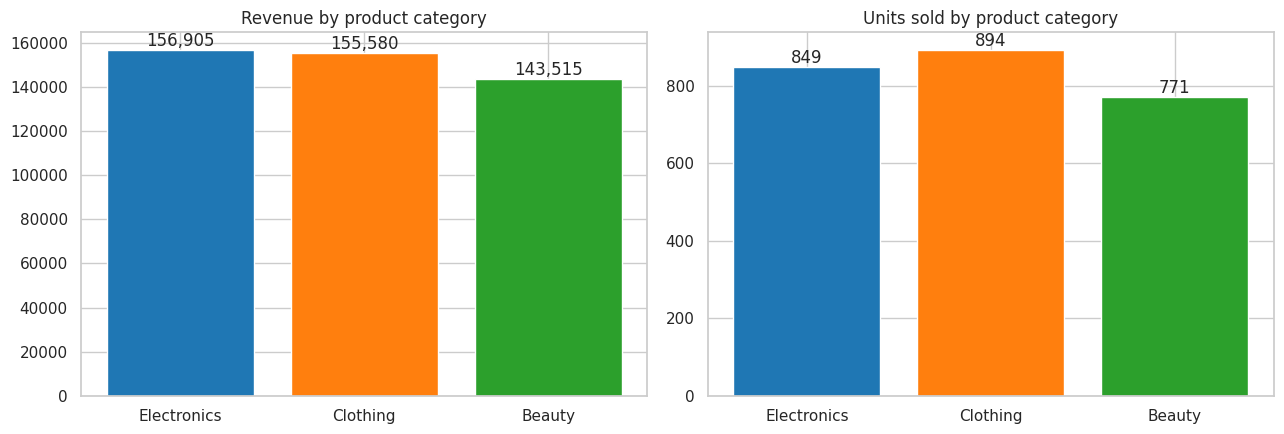

                  revenue  units  transactions  revenue_share_%
Product Category                                               
Electronics        156905    849           342             34.4
Clothing           155580    894           351             34.1
Beauty             143515    771           307             31.5

In [12]:
cat = df.groupby("Product Category").agg(
    revenue=("Total Amount", "sum"),
    units=("Quantity", "sum"),
    transactions=("Transaction ID", "count"),
).sort_values("revenue", ascending=False)
cat["revenue_share_%"] = (cat["revenue"] / cat["revenue"].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar(cat.index, cat["revenue"], color=sns.color_palette("tab10", 3))
axes[0].bar_label(bars, fmt="{:,.0f}")
axes[0].set_title("Revenue by product category")

bars = axes[1].bar(cat.index, cat["units"], color=sns.color_palette("tab10", 3))
axes[1].bar_label(bars)
axes[1].set_title("Units sold by product category")
plt.tight_layout()
plt.show()
cat

**Observations**

- The three categories are **almost equal in revenue**: Electronics **156,905 (34.4%)**, Clothing **155,580 (34.1%)**, Beauty **143,515 (31.5%)**.
- **Clothing sells the most units (894)** and has the most transactions (351), but earns slightly less than Electronics because its average price per unit is lower (about 174 vs 185). Beauty trails on both.
- No category is a clear winner or a failure: Beauty is the weakest, about 8.5% below Electronics.

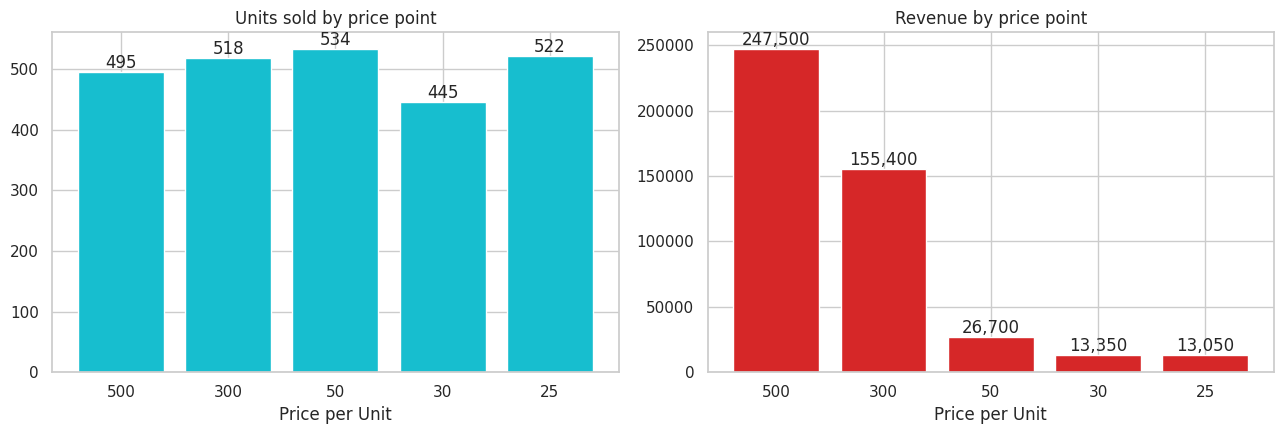

                units  revenue  transactions
Price per Unit                              
500               495   247500           199
300               518   155400           197
50                534    26700           211
30                445    13350           183
25                522    13050           210

In [13]:
# The data has no product names, so the "top products" ranking uses the 5 price points as product tiers
tier = df.groupby("Price per Unit").agg(
    units=("Quantity", "sum"),
    revenue=("Total Amount", "sum"),
    transactions=("Transaction ID", "count"),
).sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = tier.index.astype(str)
bars = axes[0].bar(order, tier["units"], color="tab:cyan")
axes[0].bar_label(bars)
axes[0].set_title("Units sold by price point"); axes[0].set_xlabel("Price per Unit")

bars = axes[1].bar(order, tier["revenue"], color="tab:red")
axes[1].bar_label(bars, fmt="{:,.0f}")
axes[1].set_title("Revenue by price point"); axes[1].set_xlabel("Price per Unit")
plt.tight_layout()
plt.show()
tier

**Observations**

- Units sold are **roughly equal across all five price points** (445 to 534 units each). Customers do not avoid expensive items.
- Revenue is not equal at all: **price 500 earns 247,500** and **price 300 earns 155,400**, while the three cheap price points (25, 30, 50) earn only 13,050, 13,350 and 26,700.
- The ranking is therefore decided by price, not popularity.

## 7. Correlation heatmap

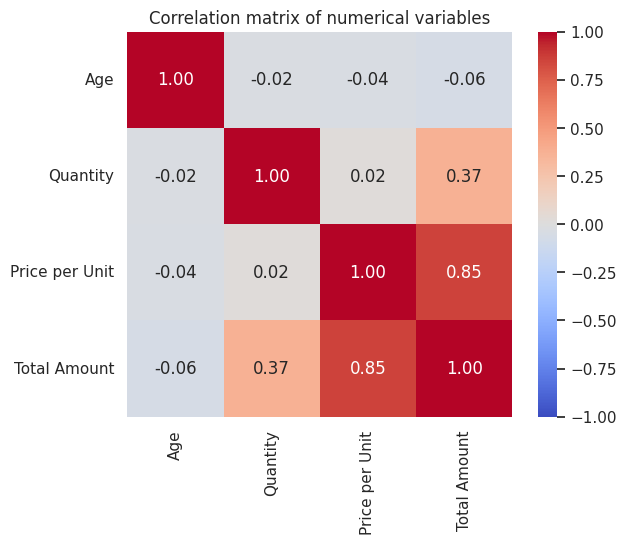

In [14]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix of numerical variables")
plt.show()

**Observations**

- **Total Amount correlates strongly with Price per Unit (0.85)** and moderately with Quantity (0.37). This is expected, since Total Amount is Quantity × Price, but it shows price matters more than quantity for revenue.
- **Quantity and Price per Unit are uncorrelated (0.02)**: people don't buy fewer items when they are expensive.
- **Age has a slight negative correlation with Total Amount (-0.06)**: very weak, but consistent with the earlier finding that younger customers spend a bit more.

## 8. Additional visualisations: finding non-obvious insights

Price 300 and 500: 39.6% of transactions -> 88.4% of revenue


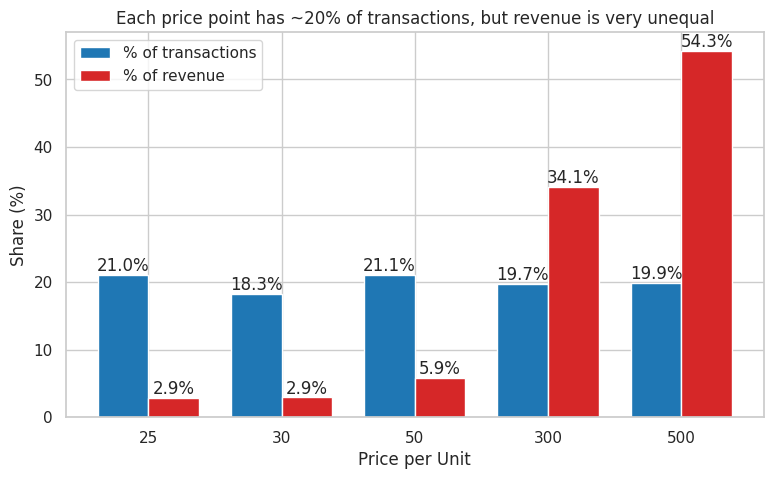

In [15]:
share = tier.copy()
share["% of transactions"] = share["transactions"] / share["transactions"].sum() * 100
share["% of revenue"] = share["revenue"] / share["revenue"].sum() * 100
share = share.sort_index()

x = np.arange(len(share)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, share["% of transactions"], w, label="% of transactions", color="tab:blue")
b2 = ax.bar(x + w/2, share["% of revenue"], w, label="% of revenue", color="tab:red")
ax.bar_label(b1, fmt="%.1f%%"); ax.bar_label(b2, fmt="%.1f%%")
ax.set_xticks(x); ax.set_xticklabels(share.index.astype(str))
ax.set_xlabel("Price per Unit"); ax.set_ylabel("Share (%)")
ax.set_title("Each price point has ~20% of transactions, but revenue is very unequal")
ax.legend()
plt.show()

high = df[df["Price per Unit"] >= 300]
print(f"Price 300 and 500: {len(high)/len(df):.1%} of transactions -> {high['Total Amount'].sum()/df['Total Amount'].sum():.1%} of revenue")

**Observation (non-obvious insight #1)**

Every price point accounts for about **20% of transactions** (18-21%). Yet the two premium price points (300 and 500) are just **39.6% of transactions** and generate **88.4% of all revenue**. The three cheap price points make up 60% of transactions but only 11.6% of revenue. **The business effectively runs on its premium items.**

It is also notable that every category sells every price point at a similar rate (e.g. Beauty sells at the 500 price point as often as Electronics: 68 vs 67 transactions). This suggests the dataset is **synthetic or randomly generated**: real retail data would show Electronics skewing expensive. I'll treat the findings as a demonstration of method, not as real-world market facts.

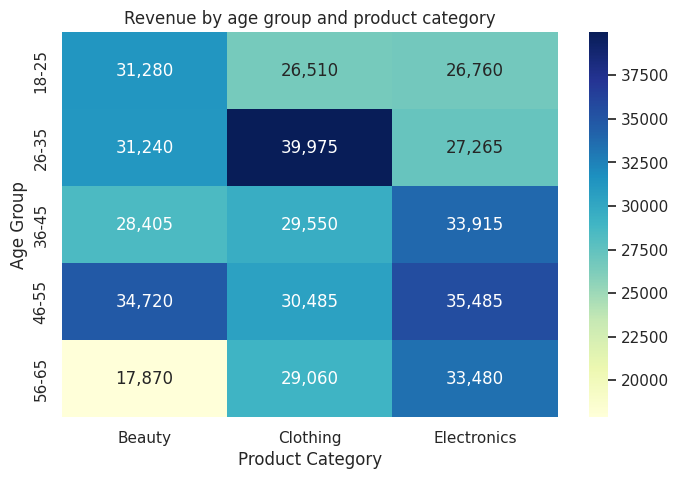

Product Category  Beauty  Clothing  Electronics
Age Group                                      
18-25              31280     26510        26760
26-35              31240     39975        27265
36-45              28405     29550        33915
46-55              34720     30485        35485
56-65              17870     29060        33480

In [16]:
pivot = df.pivot_table(index="Age Group", columns="Product Category",
                       values="Total Amount", aggfunc="sum", observed=True)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu")
plt.title("Revenue by age group and product category")
plt.show()
pivot

**Observation (non-obvious insight #2)**

Category preference changes with age, even though gender barely matters:

- **Beauty drops sharply among 56-65** (**17,870**) versus 28,405 to 34,720 in every other age group.
- **Clothing peaks with 26-35** (**39,975**, the highest single cell).
- **Electronics grows with age**, from 26,760 (18-25) to around 33,500-35,500 for ages 36+.

These are differences in revenue; part of the Beauty gap may just be random variation in a small sample (55 Beauty transactions in 56-65), so I'd treat it as a lead worth testing rather than a proven fact.

## 9. Conclusion and business recommendations

**Summary of findings:** over 2023 the store made **456,000** across 1,000 transactions (average 456, median 135). Sales were volatile, peaking in May and falling in September, with Q4 the best quarter. Customers are balanced by gender and spread across ages. Revenue is driven by *price tier*, not by category, gender or popularity.

**Recommendations**

1. **Focus stock, shelf space and marketing on the premium price points (300 and 500).** They are only about 40% of transactions but deliver **88% of revenue**. Customers buy them as often as cheap items, so there is no demand barrier. Even a small shift of buyers from cheap items to premium ones would have a large revenue effect.
2. **Run multi-buy promotions to move customers from 1-2 items to 3-4 items.** The average transaction is about 177 for 1 item versus about 707 for 4 items, and quantity is independent of price. Offers like "buy 3, get a discount" would raise basket size without hurting premium sales.
3. **Target campaigns by age, not gender.** Gender differences are tiny (455 vs 457 per transaction), but age matters: 18-25 customers spend the most per visit (500, versus 412 for 56-65). Pitch premium offers to younger shoppers, promote Clothing to 26-35, and test whether Beauty marketing aimed at 56-65 is underperforming or the category simply doesn't appeal to them.
4. **Plan promotions and inventory around the sales calendar.** September (23,620) and Q3 (96,045) were the weak spots, while May and Q4 were the strongest. Schedule promotions in the slow months and make sure stock is in place before May and Q4. Because this is one year of data, first confirm the pattern with a second year.

**Limitations:** one year of data, one purchase per customer, only three categories, and signs the dataset is synthetic. These findings show the analysis approach more than they prove real-world rules.